In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv('../../multimodal_merged_dataset.csv')

df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan
df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)

df['Event_A'] = np.where(df['MOCATOTS_clean'].notna(), (df['MOCATOTS_clean'] < 26).astype(float), np.nan)
df['Event_B'] = np.where(df['LH_ENT_clean'].notna(), (df['LH_ENT_clean'] < 1295.0).astype(float), np.nan)

ab = df[['Event_A', 'Event_B']].dropna()
N = len(ab)

counts = pd.crosstab(ab['Event_A'], ab['Event_B'], margins=True)
probs = (counts / N).round(4)

print(f"Complete-case sample size (N): {N}\n")
print("Counts Table:\n", counts, "\n")
print("Joint & Marginal Probabilities:\n", probs)

Complete-case sample size (N): 1227

Counts Table:
 Event_B  0.0  1.0   All
Event_A                
0.0      478   95   573
1.0      446  208   654
All      924  303  1227 

Joint & Marginal Probabilities:
 Event_B     0.0     1.0    All
Event_A                       
0.0      0.3896  0.0774  0.467
1.0      0.3635  0.1695  0.533
All      0.7531  0.2469  1.000


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\86801620.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\86801620.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\86801620.py:10: PerformanceWarning: DataFrame is highly fragmented.  T

In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv('../../multimodal_merged_dataset.csv')

df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan
df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)
df['HYPERTEN_clean'] = df['HYPERTEN'].where(df['HYPERTEN'].isin([0.0, 1.0, 2.0]), np.nan)

df['A'] = np.where(df['MOCATOTS_clean'].notna(), (df['MOCATOTS_clean'] < 26).astype(float), np.nan)
df['B'] = np.where(df['LH_ENT_clean'].notna(), (df['LH_ENT_clean'] < 1295.0).astype(float), np.nan)
df['C'] = np.where(df['HYPERTEN_clean'].notna(), (df['HYPERTEN_clean'] == 1.0).astype(float), np.nan)

ab = df[['A', 'B']].dropna()
p_A = ab['A'].mean()
p_A_given_B = ab.loc[ab['B'] == 1, 'A'].mean()
p_A_given_Bc = ab.loc[ab['B'] == 0, 'A'].mean()

print(f"--- Conditioning on MRI Atrophy (N={len(ab)}) ---")
print(f"Baseline P(A)   = {p_A:.4f}")
print(f"P(A | B)        = {p_A_given_B:.4f} (Change: {p_A_given_B - p_A:+.4f})")
print(f"P(A | B^c)      = {p_A_given_Bc:.4f} (Change: {p_A_given_Bc - p_A:+.4f})\n")

ac = df[['A', 'C']].dropna()
p_A_ac = ac['A'].mean()
p_A_given_C = ac.loc[ac['C'] == 1, 'A'].mean()
p_A_given_Cc = ac.loc[ac['C'] == 0, 'A'].mean()

print(f"--- Conditioning on Hypertension (N={len(ac)}) ---")
print(f"Baseline P(A)   = {p_A_ac:.4f}")
print(f"P(A | C)        = {p_A_given_C:.4f} (Change: {p_A_given_C - p_A_ac:+.4f})")
print(f"P(A | C^c)      = {p_A_given_Cc:.4f} (Change: {p_A_given_Cc - p_A_ac:+.4f})")

--- Conditioning on MRI Atrophy (N=1227) ---
Baseline P(A)   = 0.5330
P(A | B)        = 0.6865 (Change: +0.1535)
P(A | B^c)      = 0.4827 (Change: -0.0503)

--- Conditioning on Hypertension (N=1196) ---
Baseline P(A)   = 0.5276
P(A | C)        = 0.6018 (Change: +0.0742)
P(A | C^c)      = 0.4841 (Change: -0.0435)


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\902721188.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\902721188.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\902721188.py:9: PerformanceWarning: DataFrame is highly fragmented. 

In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv('../../multimodal_merged_dataset.csv')

df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan
df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)

df['A'] = np.where(df['MOCATOTS_clean'].notna(), (df['MOCATOTS_clean'] < 26).astype(float), np.nan)
df['B'] = np.where(df['LH_ENT_clean'].notna(), (df['LH_ENT_clean'] < 1295.0).astype(float), np.nan)

ab = df[['A', 'B']].dropna()
N = len(ab)

p_A = (ab['A'] == 1).mean()
p_B = (ab['B'] == 1).mean()
p_AB_obs = ((ab['A'] == 1) & (ab['B'] == 1)).mean()
p_AB_exp = p_A * p_B

p_A_given_B = ab.loc[ab['B'] == 1, 'A'].mean()
p_B_given_A = ab.loc[ab['A'] == 1, 'B'].mean()

print(f"N = {N}")
print(f"Observed P(A ∩ B) = {p_AB_obs:.4f} (Count = {int(p_AB_obs * N)})")
print(f"Expected P(A)P(B) = {p_AB_exp:.4f} (Expected Count = {p_AB_exp * N:.2f})")
print(f"Difference        = {p_AB_obs - p_AB_exp:+.4f} ({(p_AB_obs - p_AB_exp)*N:+.2f} subjects)\n")
print(f"P(A | B) = {p_A_given_B:.4f} vs P(A) = {p_A:.4f}")
print(f"P(B | A) = {p_B_given_A:.4f} vs P(B) = {p_B:.4f}")

N = 1227
Observed P(A ∩ B) = 0.1695 (Count = 208)
Expected P(A)P(B) = 0.1316 (Expected Count = 161.50)
Difference        = +0.0379 (+46.50 subjects)

P(A | B) = 0.6865 vs P(A) = 0.5330
P(B | A) = 0.3180 vs P(B) = 0.2469


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\1354267140.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\1354267140.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\1354267140.py:10: PerformanceWarning: DataFrame is highly fragment

C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\1261782003.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)


N = 1228, p_hat = 0.5326
Binomial(n=20, p=0.5326) -> E[S]=10.65, Var(S)=4.98, SD(S)=2.23
P(S = 11)        = 0.1749
P(S >= 10)       = 0.6978
P(8 <= S <= 13)  = 0.8214

Heterogeneity of p across Age Groups:
           count    mean
Age_Group               
<65          435  0.4023
65-75        558  0.5753
>75          235  0.6723


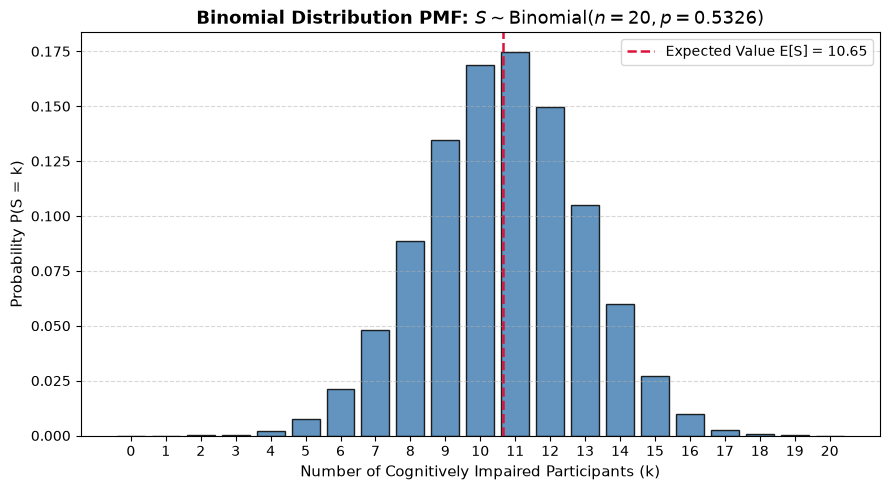

In [8]:
import pandas as pd
import numpy as np
from scipy.stats import binom
import matplotlib.pyplot as plt

df = pd.read_csv('../../multimodal_merged_dataset.csv')
df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan

valid_moca = df[df['MOCATOTS_clean'].notna()].copy()
valid_moca['A'] = (valid_moca['MOCATOTS_clean'] < 26).astype(int)

N = len(valid_moca)
p_hat = valid_moca['A'].mean()
n = 20

exp_val = n * p_hat
var_val = n * p_hat * (1 - p_hat)
std_val = np.sqrt(var_val)

print(f"N = {N}, p_hat = {p_hat:.4f}")
print(f"Binomial(n={n}, p={p_hat:.4f}) -> E[S]={exp_val:.2f}, Var(S)={var_val:.2f}, SD(S)={std_val:.2f}")
print(f"P(S = 11)        = {binom.pmf(11, n, p_hat):.4f}")
print(f"P(S >= 10)       = {1 - binom.cdf(9, n, p_hat):.4f}")
print(f"P(8 <= S <= 13)  = {binom.cdf(13, n, p_hat) - binom.cdf(7, n, p_hat):.4f}\n")

valid_moca['Age_Group'] = pd.cut(valid_moca['NACCAGE'], bins=[40, 65, 75, 100], labels=['<65', '65-75', '>75'])
print("Heterogeneity of p across Age Groups:")
print(valid_moca.groupby('Age_Group', observed=False)['A'].agg(['count', 'mean']).round(4))

k_vals = np.arange(0, n + 1)
pmf_vals = binom.pmf(k_vals, n, p_hat)

plt.figure(figsize=(9, 5))
plt.bar(k_vals, pmf_vals, color='steelblue', edgecolor='black', alpha=0.85)
plt.axvline(exp_val, color='crimson', linestyle='--', linewidth=1.8, label=f'Expected Value E[S] = {exp_val:.2f}')
plt.title(f'Binomial Distribution PMF: $S \\sim \\mathrm{{Binomial}}(n={n}, p={p_hat:.4f})$', fontsize=13, fontweight='bold')
plt.xlabel('Number of Cognitively Impaired Participants (k)', fontsize=11)
plt.ylabel('Probability P(S = k)', fontsize=11)
plt.xticks(k_vals)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('binomial_pmf_n20.png', dpi=300)
plt.show()

N = 1237 | Mean = 2.5948 | Median = 2.5940 | SD = 0.2833
Skewness = -0.1605 | Excess Kurtosis = 0.1944
Within 1 SD: 68.31% | 2 SD: 95.55% | 3 SD: 99.60%
P(Y < 2.2)        -> Empirical: 0.0816 | Normal: 0.0817
P(2.3 <= Y <= 2.9)-> Empirical: 0.7090 | Normal: 0.7103
P(Y > 3.0)        -> Empirical: 0.0711 | Normal: 0.0763


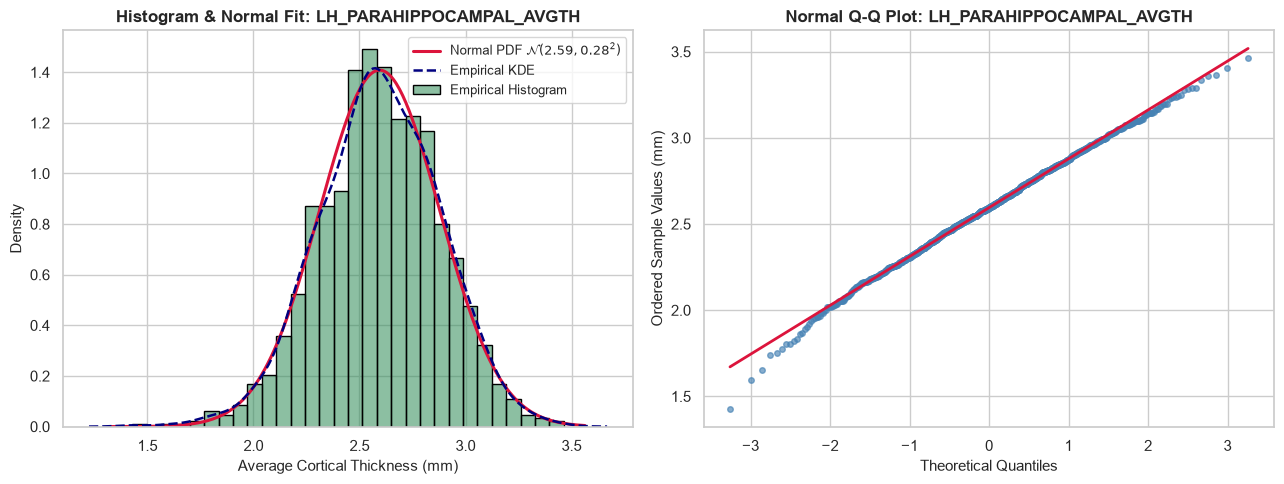

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('../../multimodal_merged_dataset.csv')
y = df['LH_PARAHIPPOCAMPAL_AVGTH'].dropna()

mu = y.mean()
med = y.median()
sigma = y.std(ddof=1)
skew = stats.skew(y)
kurt = stats.kurtosis(y)

within_1sd = ((y >= mu - sigma) & (y <= mu + sigma)).mean() * 100
within_2sd = ((y >= mu - 2*sigma) & (y <= mu + 2*sigma)).mean() * 100
within_3sd = ((y >= mu - 3*sigma) & (y <= mu + 3*sigma)).mean() * 100

print(f"N = {len(y)} | Mean = {mu:.4f} | Median = {med:.4f} | SD = {sigma:.4f}")
print(f"Skewness = {skew:.4f} | Excess Kurtosis = {kurt:.4f}")
print(f"Within 1 SD: {within_1sd:.2f}% | 2 SD: {within_2sd:.2f}% | 3 SD: {within_3sd:.2f}%")

print(f"P(Y < 2.2)        -> Empirical: {(y < 2.2).mean():.4f} | Normal: {stats.norm.cdf(2.2, mu, sigma):.4f}")
print(f"P(2.3 <= Y <= 2.9)-> Empirical: {((y >= 2.3) & (y <= 2.9)).mean():.4f} | Normal: {stats.norm.cdf(2.9, mu, sigma) - stats.norm.cdf(2.3, mu, sigma):.4f}")
print(f"P(Y > 3.0)        -> Empirical: {(y > 3.0).mean():.4f} | Normal: {1 - stats.norm.cdf(3.0, mu, sigma):.4f}")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(y, bins=30, stat='density', color='seagreen', alpha=0.55, edgecolor='black', ax=axes[0], label='Empirical Histogram')
x_grid = np.linspace(y.min() - 0.1, y.max() + 0.1, 300)
axes[0].plot(x_grid, stats.norm.pdf(x_grid, mu, sigma), color='crimson', linewidth=2.2, label=f'Normal PDF $\\mathcal{{N}}({mu:.2f}, {sigma:.2f}^2)$')
sns.kdeplot(y, color='navy', linestyle='--', linewidth=1.8, ax=axes[0], label='Empirical KDE')
axes[0].set_title('Histogram & Normal Fit: LH_PARAHIPPOCAMPAL_AVGTH', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Average Cortical Thickness (mm)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)
axes[0].legend(fontsize=9.5)

stats.probplot(y, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_markerfacecolor('steelblue')
axes[1].get_lines()[0].set_markeredgecolor('steelblue')
axes[1].get_lines()[0].set_markersize(4)
axes[1].get_lines()[0].set_alpha(0.65)
axes[1].get_lines()[1].set_color('crimson')
axes[1].get_lines()[1].set_linewidth(2)
axes[1].set_title('Normal Q-Q Plot: LH_PARAHIPPOCAMPAL_AVGTH', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Theoretical Quantiles', fontsize=11)
axes[1].set_ylabel('Ordered Sample Values (mm)', fontsize=11)

plt.tight_layout()
plt.savefig('normal_fit_qq_parahippo.png', dpi=300)
plt.show()

In [12]:
import pandas as pd
import numpy as np

df = pd.read_csv('../../multimodal_merged_dataset.csv')
df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan

x = df['MOCATOTS_clean'].dropna()
y = df['LH_PARAHIPPOCAMPAL_AVGTH'].dropna()

for name, s in [('X: MOCATOTS (points)', x), ('Y: LH_PARAHIPPOCAMPAL_AVGTH (mm)', y)]:
    mean_val = s.mean()
    var_emp = s.var(ddof=0)
    var_samp = s.var(ddof=1)
    sd_samp = s.std(ddof=1)
    cv = (sd_samp / mean_val) * 100
    print(f"=== {name} (N={len(s)}) ===")
    print(f"E[V] = {mean_val:.4f} | Var_emp = {var_emp:.4f} | Var_sample = {var_samp:.4f} | SD = {sd_samp:.4f} | CV = {cv:.2f}%\n")

=== X: MOCATOTS (points) (N=1228) ===
E[V] = 24.3930 | Var_emp = 19.5631 | Var_sample = 19.5791 | SD = 4.4248 | CV = 18.14%

=== Y: LH_PARAHIPPOCAMPAL_AVGTH (mm) (N=1237) ===
E[V] = 2.5948 | Var_emp = 0.0802 | Var_sample = 0.0803 | SD = 0.2833 | CV = 10.92%



C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\755021996.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\2993770615.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)


Complete-case N = 1228
Mean X (MOCATOTS) = 24.3930 | Mean Y (LH_PARAHIPPOCAMPAL_AVGTH) = 2.5953
Empirical Covariance (ddof=0) = 0.2672
Sample Covariance    (ddof=1) = 0.2674


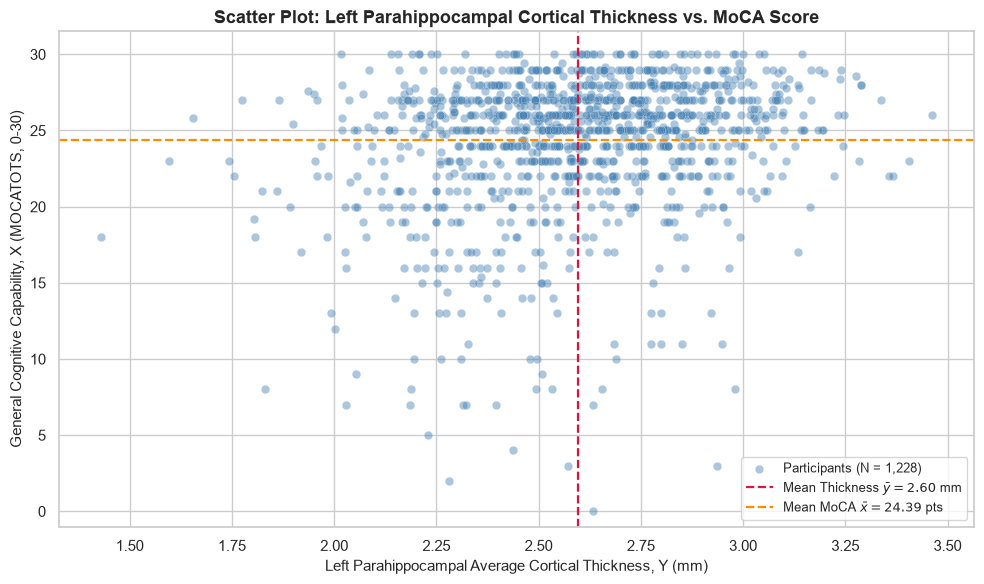

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../../multimodal_merged_dataset.csv')
df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan

xy = df[['MOCATOTS_clean', 'LH_PARAHIPPOCAMPAL_AVGTH']].dropna()
x = xy['MOCATOTS_clean']
y = xy['LH_PARAHIPPOCAMPAL_AVGTH']
N = len(xy)

mean_x, mean_y = x.mean(), y.mean()
cov_emp = np.cov(x, y, ddof=0)[0, 1]
cov_samp = np.cov(x, y, ddof=1)[0, 1]

print(f"Complete-case N = {N}")
print(f"Mean X (MOCATOTS) = {mean_x:.4f} | Mean Y (LH_PARAHIPPOCAMPAL_AVGTH) = {mean_y:.4f}")
print(f"Empirical Covariance (ddof=0) = {cov_emp:.4f}")
print(f"Sample Covariance    (ddof=1) = {cov_samp:.4f}")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

plt.scatter(y, x, alpha=0.45, color='steelblue', edgecolor='white', linewidth=0.3, s=38, label=f'Participants (N = {N:,})')
plt.axvline(mean_y, color='crimson', linestyle='--', linewidth=1.6, label=f'Mean Thickness $\\bar{{y}} = {mean_y:.2f}$ mm')
plt.axhline(mean_x, color='darkorange', linestyle='--', linewidth=1.6, label=f'Mean MoCA $\\bar{{x}} = {mean_x:.2f}$ pts')

plt.title('Scatter Plot: Left Parahippocampal Cortical Thickness vs. MoCA Score', fontsize=13, fontweight='bold')
plt.xlabel('Left Parahippocampal Average Cortical Thickness, Y (mm)', fontsize=11)
plt.ylabel('General Cognitive Capability, X (MOCATOTS, 0-30)', fontsize=11)
plt.ylim(-1, 31.5)
plt.legend(loc='lower right', fontsize=9.5, frameon=True)
plt.tight_layout()
plt.savefig('scatter_cov_moca_parahippo.png', dpi=300)
plt.show()

In [14]:
import pandas as pd
import numpy as np

df = pd.read_csv('../../multimodal_merged_dataset.csv')
df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan
df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)

df['A'] = np.where(df['MOCATOTS_clean'].notna(), (df['MOCATOTS_clean'] < 26).astype(float), np.nan)
df['B'] = np.where(df['LH_ENT_clean'].notna(), (df['LH_ENT_clean'] < 1295.0).astype(float), np.nan)

ab = df[['A', 'B']].dropna()
N = len(ab)

p_A = (ab['A'] == 1).mean()
p_Ac = 1 - p_A

p_B_given_A = ab.loc[ab['A'] == 1, 'B'].mean()
p_B_given_Ac = ab.loc[ab['A'] == 0, 'B'].mean()

p_B = p_B_given_A * p_A + p_B_given_Ac * p_Ac
p_A_given_B = (p_B_given_A * p_A) / p_B

p_Bc_given_A = 1 - p_B_given_A
p_Bc_given_Ac = 1 - p_B_given_Ac
p_Bc = p_Bc_given_A * p_A + p_Bc_given_Ac * p_Ac
p_A_given_Bc = (p_Bc_given_A * p_A) / p_Bc

print(f"N = {N}")
print(f"Prior P(A) = {p_A:.4f} | P(A^c) = {p_Ac:.4f}")
print(f"Likelihoods: P(B|A) = {p_B_given_A:.4f} | P(B|A^c) = {p_B_given_Ac:.4f}")
print(f"Total Probability P(B) = {p_B:.4f}")
print(f"Posterior P(A|B)   = {p_A_given_B:.4f} (Shift: {(p_A_given_B - p_A)*100:+.2f} pp)")
print(f"Posterior P(A|B^c) = {p_A_given_Bc:.4f} (Shift: {(p_A_given_Bc - p_A)*100:+.2f} pp)")

N = 1227
Prior P(A) = 0.5330 | P(A^c) = 0.4670
Likelihoods: P(B|A) = 0.3180 | P(B|A^c) = 0.1658
Total Probability P(B) = 0.2469
Posterior P(A|B)   = 0.6865 (Shift: +15.35 pp)
Posterior P(A|B^c) = 0.4827 (Shift: -5.03 pp)


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\3488429496.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\3488429496.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\3488429496.py:9: PerformanceWarning: DataFrame is highly fragmente

In [15]:
import pandas as pd
import numpy as np

df = pd.read_csv('../../multimodal_merged_dataset.csv')

df['Clinical_Impairment'] = df['NACCUDSD'].isin([3.0, 4.0]).astype(int)
df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)

print(f"Baseline P(MCI or Dementia) = {df['Clinical_Impairment'].mean():.4f} ({df['Clinical_Impairment'].sum()}/{len(df)})\n")

q1_thick = df['LH_PARAHIPPOCAMPAL_AVGTH'].quantile(0.25)
df['MRI_Thinning'] = np.where(df['LH_PARAHIPPOCAMPAL_AVGTH'] < q1_thick,
                              'Low Thickness (< Q1)', 'Normal/High Thickness (>= Q1)')

print(f"--- Grouping 1: MRI-Only (Q1 = {q1_thick:.3f} mm) ---")
print(df.groupby('MRI_Thinning')['Clinical_Impairment'].agg(['count', 'sum', 'mean']).round(4), "\n")

sub = df.dropna(subset=['LH_ENT_clean']).copy()
sub['Age_70'] = np.where(sub['NACCAGE'] >= 70, 'Age >= 70', 'Age < 70')
sub['Ent_Low'] = np.where(sub['LH_ENT_clean'] < 1295.0, 'Low Ent. Vol.', 'Normal/High Ent. Vol.')
sub['Multimodal_Group'] = sub['Age_70'] + ' & ' + sub['Ent_Low']

print(f"--- Grouping 2: Combined UDS (Age) + MRI (Entorhinal Vol.), N = {len(sub)} ---")
print(sub.groupby('Multimodal_Group')['Clinical_Impairment'].agg(['count', 'sum', 'mean']).sort_values('mean').round(4))

Baseline P(MCI or Dementia) = 0.3096 (383/1237)

--- Grouping 1: MRI-Only (Q1 = 2.406 mm) ---
                               count  sum    mean
MRI_Thinning                                     
Low Thickness (< Q1)             307  146  0.4756
Normal/High Thickness (>= Q1)    930  237  0.2548 

--- Grouping 2: Combined UDS (Age) + MRI (Entorhinal Vol.), N = 1236 ---
                                   count  sum    mean
Multimodal_Group                                     
Age < 70 & Normal/High Ent. Vol.     558  115  0.2061
Age >= 70 & Normal/High Ent. Vol.    372  123  0.3306
Age < 70 & Low Ent. Vol.             126   50  0.3968
Age >= 70 & Low Ent. Vol.            180   95  0.5278


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\2122012913.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Clinical_Impairment'] = df['NACCUDSD'].isin([3.0, 4.0]).astype(int)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\2122012913.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['LH_ENT_clean'] = df['LH_ENTORHINAL_GVOL'].where(df['LH_ENTORHINAL_GVOL'] > 0, np.nan)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\2122012913.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resul

C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\2128198679.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)


=== MOCATOTS (UDS) (N=1228) ===
Mean = 24.3930 | Median = 25.4000 | Var = 19.5791 | SD = 4.4248
Skewness = -1.8295 | Excess Kurtosis = 4.5411
Fences: [17.00, 33.00] -> Low outliers: 76, High outliers: 0

=== LH_PARAHIPPOCAMPAL_AVGTH (MRI) (N=1237) ===
Mean = 2.5948 | Median = 2.5940 | Var = 0.0803 | SD = 0.2833
Skewness = -0.1605 | Excess Kurtosis = 0.1944
Fences: [1.82, 3.38] -> Low outliers: 8, High outliers: 2



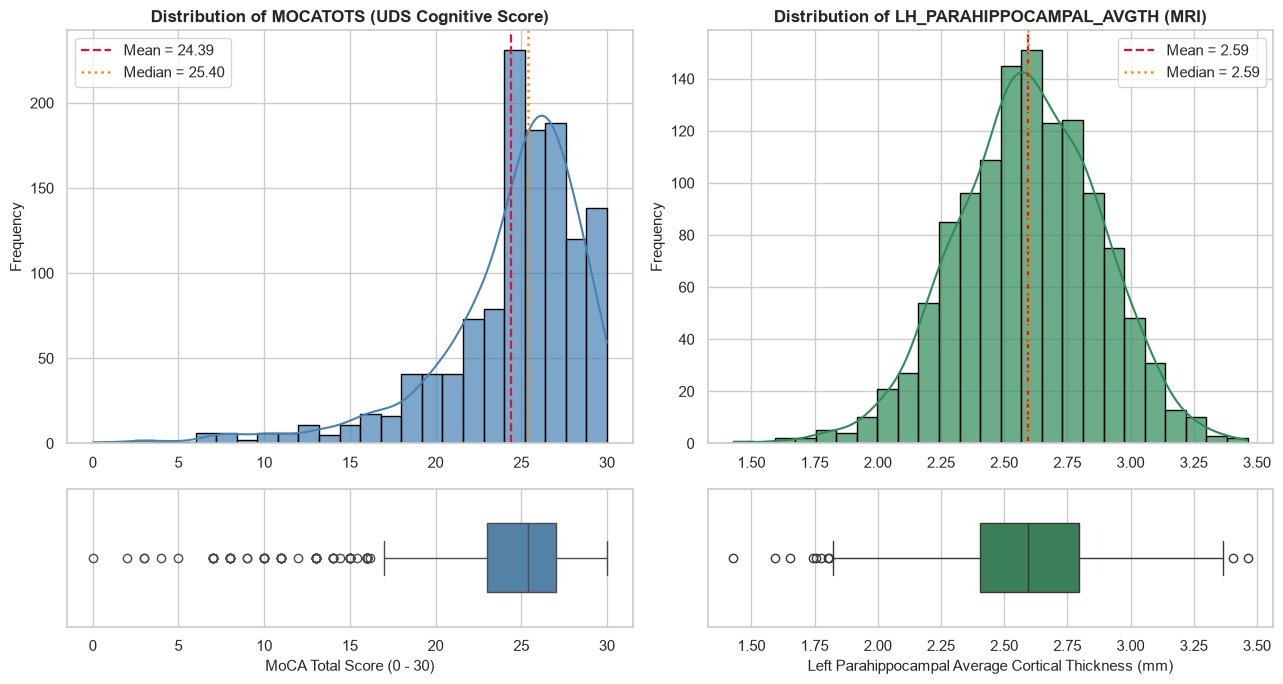

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('../../multimodal_merged_dataset.csv')
df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan

x = df['MOCATOTS_clean'].dropna()
y = df['LH_PARAHIPPOCAMPAL_AVGTH'].dropna()

for name, s in [('MOCATOTS (UDS)', x), ('LH_PARAHIPPOCAMPAL_AVGTH (MRI)', y)]:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low_f, high_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_low, n_high = (s < low_f).sum(), (s > high_f).sum()
    print(f"=== {name} (N={len(s)}) ===")
    print(f"Mean = {s.mean():.4f} | Median = {s.median():.4f} | Var = {s.var(ddof=1):.4f} | SD = {s.std(ddof=1):.4f}")
    print(f"Skewness = {stats.skew(s):.4f} | Excess Kurtosis = {stats.kurtosis(s):.4f}")
    print(f"Fences: [{low_f:.2f}, {high_f:.2f}] -> Low outliers: {n_low}, High outliers: {n_high}\n")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={'height_ratios': [3, 1]})

sns.histplot(x, bins=25, kde=True, color='steelblue', edgecolor='black', alpha=0.7, ax=axes[0, 0])
axes[0, 0].axvline(x.mean(), color='crimson', linestyle='--', linewidth=1.6, label=f'Mean = {x.mean():.2f}')
axes[0, 0].axvline(x.median(), color='darkorange', linestyle=':', linewidth=1.8, label=f'Median = {x.median():.2f}')
axes[0, 0].set_title('Distribution of MOCATOTS (UDS Cognitive Score)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Frequency', fontsize=11)
axes[0, 0].legend()
sns.boxplot(x=x, color='steelblue', width=0.5, ax=axes[1, 0])
axes[1, 0].set_xlabel('MoCA Total Score (0 - 30)', fontsize=11)

sns.histplot(y, bins=25, kde=True, color='seagreen', edgecolor='black', alpha=0.7, ax=axes[0, 1])
axes[0, 1].axvline(y.mean(), color='crimson', linestyle='--', linewidth=1.6, label=f'Mean = {y.mean():.2f}')
axes[0, 1].axvline(y.median(), color='darkorange', linestyle=':', linewidth=1.8, label=f'Median = {y.median():.2f}')
axes[0, 1].set_title('Distribution of LH_PARAHIPPOCAMPAL_AVGTH (MRI)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Frequency', fontsize=11)
axes[0, 1].legend()
sns.boxplot(x=y, color='seagreen', width=0.5, ax=axes[1, 1])
axes[1, 1].set_xlabel('Left Parahippocampal Average Cortical Thickness (mm)', fontsize=11)

plt.tight_layout()
plt.savefig('c2_dist_moca_parahippo.png', dpi=300)
plt.show()

In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv('../../multimodal_merged_dataset.csv')
N = len(df)

df['D'] = df['NACCUDSD'].isin([3.0, 4.0]).astype(int)

q1_lh = df['LH_ENTORHINAL_AVGTH'].quantile(0.25)
q1_rh = df['RH_ENTORHINAL_AVGTH'].quantile(0.25)
df['M'] = ((df['LH_ENTORHINAL_AVGTH'] < q1_lh) & (df['RH_ENTORHINAL_AVGTH'] < q1_rh)).astype(int)

counts = pd.crosstab(df['D'], df['M'], margins=True)
probs = (counts / N).round(4)

p_D = df['D'].mean()
p_M = df['M'].mean()
p_DM = ((df['D'] == 1) & (df['M'] == 1)).mean()
p_D_given_M = df.loc[df['M'] == 1, 'D'].mean()
p_D_given_Mc = df.loc[df['M'] == 0, 'D'].mean()
p_M_given_D = df.loc[df['D'] == 1, 'M'].mean()
p_M_given_Dc = df.loc[df['D'] == 0, 'M'].mean()

print(f"N = {N} | Q1(LH) = {q1_lh:.3f} mm, Q1(RH) = {q1_rh:.3f} mm\n")
print("Counts:\n", counts, "\n")
print("Probabilities:\n", probs, "\n")
print(f"P(D) = {p_D:.4f} | P(M) = {p_M:.4f} | P(D ∩ M) = {p_DM:.4f}")
print(f"P(D | M) = {p_D_given_M:.4f} vs P(D | M^c) = {p_D_given_Mc:.4f}")
print(f"P(M | D) = {p_M_given_D:.4f} vs P(M | D^c) = {p_M_given_Dc:.4f}")

N = 1237 | Q1(LH) = 2.763 mm, Q1(RH) = 2.852 mm

Counts:
 M       0    1   All
D                   
0     779   75   854
1     273  110   383
All  1052  185  1237 

Probabilities:
 M         0       1     All
D                          
0    0.6297  0.0606  0.6904
1    0.2207  0.0889  0.3096
All  0.8504  0.1496  1.0000 

P(D) = 0.3096 | P(M) = 0.1496 | P(D ∩ M) = 0.0889
P(D | M) = 0.5946 vs P(D | M^c) = 0.2595
P(M | D) = 0.2872 vs P(M | D^c) = 0.0878


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\2413666139.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['D'] = df['NACCUDSD'].isin([3.0, 4.0]).astype(int)
C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\2413666139.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['M'] = ((df['LH_ENTORHINAL_AVGTH'] < q1_lh) & (df['RH_ENTORHINAL_AVGTH'] < q1_rh)).astype(int)


C:\Users\lotus\AppData\Local\Temp\ipykernel_18584\1707089515.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)


Complete-case N = 1228
Mean X (MOCATOTS) = 24.3930 | Mean Y (LH_ENTORHINAL_AVGTH) = 2.9712
Empirical Covariance (ddof=0) = 0.4995
Sample Covariance    (ddof=1) = 0.4999


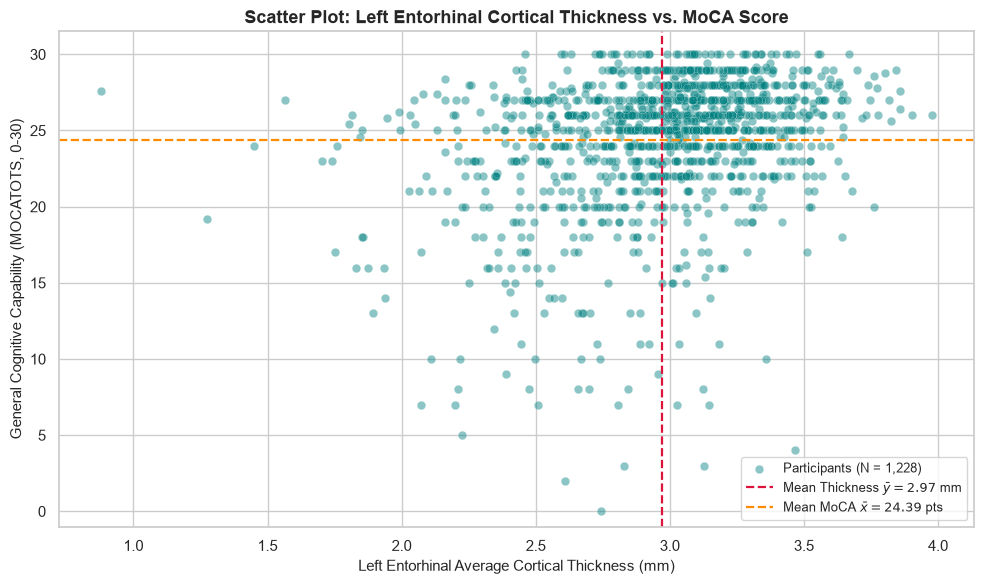

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../../multimodal_merged_dataset.csv')
df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan

xy = df[['MOCATOTS_clean', 'LH_ENTORHINAL_AVGTH']].dropna()
x = xy['MOCATOTS_clean']
y = xy['LH_ENTORHINAL_AVGTH']
N = len(xy)

mean_x, mean_y = x.mean(), y.mean()
cov_emp = np.cov(x, y, ddof=0)[0, 1]
cov_samp = np.cov(x, y, ddof=1)[0, 1]

print(f"Complete-case N = {N}")
print(f"Mean X (MOCATOTS) = {mean_x:.4f} | Mean Y (LH_ENTORHINAL_AVGTH) = {mean_y:.4f}")
print(f"Empirical Covariance (ddof=0) = {cov_emp:.4f}")
print(f"Sample Covariance    (ddof=1) = {cov_samp:.4f}")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

plt.scatter(y, x, alpha=0.45, color='teal', edgecolor='white', linewidth=0.3, s=38, label=f'Participants (N = {N:,})')
plt.axvline(mean_y, color='crimson', linestyle='--', linewidth=1.6, label=f'Mean Thickness $\\bar{{y}} = {mean_y:.2f}$ mm')
plt.axhline(mean_x, color='darkorange', linestyle='--', linewidth=1.6, label=f'Mean MoCA $\\bar{{x}} = {mean_x:.2f}$ pts')

plt.title('Scatter Plot: Left Entorhinal Cortical Thickness vs. MoCA Score', fontsize=13, fontweight='bold')
plt.xlabel('Left Entorhinal Average Cortical Thickness (mm)', fontsize=11)
plt.ylabel('General Cognitive Capability (MOCATOTS, 0-30)', fontsize=11)
plt.ylim(-1, 31.5)
plt.legend(loc='lower right', fontsize=9.5, frameon=True)
plt.tight_layout()
plt.savefig('c4_scatter_cov_moca_entorhinal.png', dpi=300)
plt.show()

In [19]:
import pandas as pd

df = pd.read_csv('../../multimodal_merged_dataset.csv')

total_rows = len(df)
unique_ids = df['NACCID'].nunique()
dup_count = df['NACCID'].duplicated(keep='first').sum()
null_id_count = df['NACCID'].isna().sum()

print(f"Total rows: {total_rows}")
print(f"Unique NACCID count: {unique_ids}")
print(f"Missing NACCID count: {null_id_count}")
print(f"Duplicate rows (keep='first'): {dup_count}")
print(f"Is NACCID strictly unique? {df['NACCID'].is_unique}")

df_dedup = df.drop_duplicates(subset=['NACCID'], keep='first').copy()
assert len(df_dedup) == unique_ids, "Uniqueness check failed!"
print(f"Verified independent participant-level sample size: N = {len(df_dedup)}")

Total rows: 1237
Unique NACCID count: 1237
Missing NACCID count: 0
Duplicate rows (keep='first'): 0
Is NACCID strictly unique? True
Verified independent participant-level sample size: N = 1237
